In [2]:
import pandas as pd
import numpy as np
import matplotlib



In [3]:
df=pd.read_csv("../data/stress_detection.csv")

print("shape",df.shape)
df.head()

shape (3000, 20)


,participant_id,day,PSS_score,Openness,Conscientiousness,Extraversion,Agreeableness,Neuroticism,sleep_time,wake_time,sleep_duration,PSQI_score,call_duration,num_calls,num_sms,screen_on_time,skin_conductance,accelerometer,mobility_radius,mobility_distance
0,1,1,34,2.322732,4.332193,1.185878,1.570213,3.782094,7.726792,5.190660,6.572069,1,3.924527,12,32,10.703714,3.115730,0.161717,1.145179,2.196851
1,1,2,37,1.761436,3.254120,3.907281,4.072512,1.997145,7.312674,6.170717,8.030168,4,58.318004,3,41,11.012939,0.959144,0.985587,1.021133,0.737825
2,1,3,30,3.025887,1.855002,2.045900,2.317493,3.619225,6.992060,5.318825,7.102420,1,4.941043,4,48,4.877372,3.311629,1.877445,0.478179,0.911673
3,1,4,16,1.948370,4.966676,3.345225,1.607756,3.583524,8.886914,8.061075,8.123294,3,0.295373,11,38,3.462956,0.625721,0.494921,0.630549,3.911418
4,1,5,32,3.343484,2.065936,3.137843,2.118061,2.567347,7.811705,7.312145,7.785143,3,22.300571,17,17,4.861046,0.622609,1.342600,0.254090,1.605132


In [4]:
df.isnull().sum()
df.duplicated().sum()
df["participant_id"].nunique()
df["PSS_score"].describe()
df["PSS_score"].value_counts().sort_index()

PSS_score
10     69
11    106
12    113
13     90
14    117
15    103
16     83
17    118
18     91
19     77
20     88
21     96
22    112
23    111
24     99
25     95
26     90
27     96
28     94
29    109
30    117
31    113
32    108
33    119
34     87
35    102
36     91
37     91
38    118
39     97
Name: count, dtype: int64

In [5]:
print("Participants:",df["participant_id"].unique())
print("Duplicate rows:",df.duplicated().sum)
print("Rows per participant:")
print(df.groupby("participant_id").size().value_counts().sort_index())

Participants: [  1   2   3   4   5   6   7   8   9  10  11  12  13  14  15  16  17  18
  19  20  21  22  23  24  25  26  27  28  29  30  31  32  33  34  35  36
  37  38  39  40  41  42  43  44  45  46  47  48  49  50  51  52  53  54
  55  56  57  58  59  60  61  62  63  64  65  66  67  68  69  70  71  72
  73  74  75  76  77  78  79  80  81  82  83  84  85  86  87  88  89  90
  91  92  93  94  95  96  97  98  99 100]
Duplicate rows: <bound method Series.sum of 0       False
1       False
2       False
3       False
4       False
        ...  
2995    False
2996    False
2997    False
2998    False
2999    False
Length: 3000, dtype: bool>
Rows per participant:
30    100
Name: count, dtype: int64


In [6]:
print("Duplicate row:",df.duplicated().sum())

Duplicate row: 0


In [7]:
from sklearn.model_selection import GroupShuffleSplit

features = [
    "Openness",
    "Conscientiousness",
    "Extraversion",
    "Agreeableness",
    "Neuroticism",
    "sleep_time",
    "wake_time",
    "sleep_duration",
    "PSQI_score",
    "call_duration",
    "num_calls",
    "num_sms",
    "screen_on_time",
    "skin_conductance",
    "accelerometer",
    "mobility_radius",
    "mobility_distance"
]

X = df[features]
y = df["PSS_score"]
groups = df["participant_id"]

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X, y, groups)
)

X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]

y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Training participants:", df.iloc[train_idx]["participant_id"].nunique())
print("Testing participants:", df.iloc[test_idx]["participant_id"].nunique())

Training samples: 2400
Testing samples: 600
Training participants: 80
Testing participants: 20


In [8]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

model = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("RMSE:", rmse)
print("R²:", r2)


MAE: 7.7431833333333335
RMSE: 8.90526833303373
R²: -0.02755929804956292


In [9]:
import pandas as pd

importance = pd.Series(
    model.feature_importances_,
    index=features
).sort_values(ascending=False)

print(importance)

sleep_time           0.066110
call_duration        0.065808
Extraversion         0.065591
Agreeableness        0.064837
screen_on_time       0.064711
wake_time            0.064456
sleep_duration       0.064190
accelerometer        0.064180
Conscientiousness    0.064168
skin_conductance     0.063967
mobility_distance    0.062697
Openness             0.061791
Neuroticism          0.061268
mobility_radius      0.060093
num_sms              0.048961
num_calls            0.040428
PSQI_score           0.016746
dtype: float64


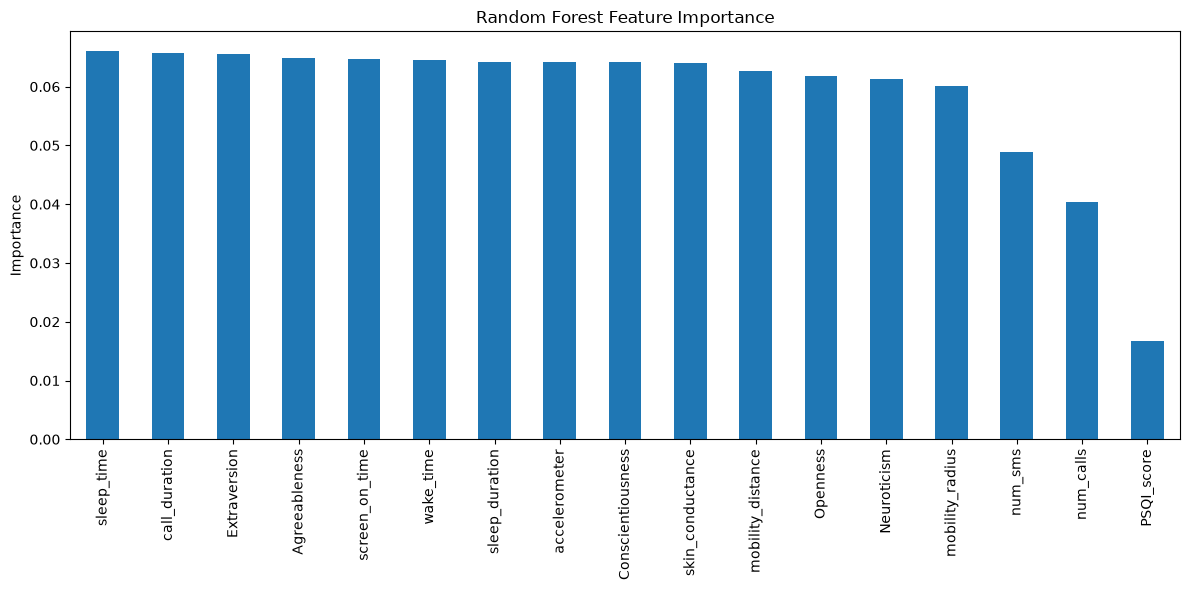

In [10]:
import matplotlib.pyplot as plt

importance.plot(kind="bar", figsize=(12, 6))
plt.title("Random Forest Feature Importance")
plt.ylabel("Importance")
plt.tight_layout()
plt.show()

In [11]:
from sklearn.model_selection import GroupShuffleSplit

features = [
    "Openness",
    "Conscientiousness",
    "Extraversion",
    "Agreeableness",
    "Neuroticism",
    "sleep_time",
    "wake_time",
    "sleep_duration",
    "PSQI_score",
    "call_duration",
    "num_calls",
    "num_sms",
    "screen_on_time",
    "skin_conductance",
    "accelerometer",
    "mobility_radius",
    "mobility_distance"
]

X = df[features]
y = df["PSS_score"]
groups = df["participant_id"]

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X, y, groups)
)

X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]

y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Training participants:", df.iloc[train_idx]["participant_id"].nunique())
print("Testing participants:", df.iloc[test_idx]["participant_id"].nunique())

Training samples: 2400
Testing samples: 600
Training participants: 80
Testing participants: 20


In [12]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=200,
        random_state=42
    )
}

for name, model in models.items():
    model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r2 = r2_score(y_test, predictions)

    print(f"\n{name}")
    print(f"MAE: {mae:.3f}")
    print(f"RMSE: {rmse:.3f}")
    print(f"R²: {r2:.3f}")


Linear Regression
MAE: 7.690
RMSE: 8.805
R²: -0.005

Random Forest
MAE: 7.743
RMSE: 8.905
R²: -0.028

Gradient Boosting
MAE: 7.858
RMSE: 9.046
R²: -0.060


In [13]:
correlations = df[features + ["PSS_score"]].corr()["PSS_score"].sort_values()

print(correlations)

mobility_distance   -0.034954
num_calls           -0.028919
PSQI_score          -0.021299
sleep_time          -0.018059
sleep_duration      -0.014899
wake_time           -0.004925
Agreeableness       -0.003250
screen_on_time       0.004377
accelerometer        0.004656
call_duration        0.006049
Openness             0.007923
mobility_radius      0.008731
Extraversion         0.010655
Conscientiousness    0.011215
Neuroticism          0.015813
skin_conductance     0.016004
num_sms              0.035045
PSS_score            1.000000
Name: PSS_score, dtype: float64


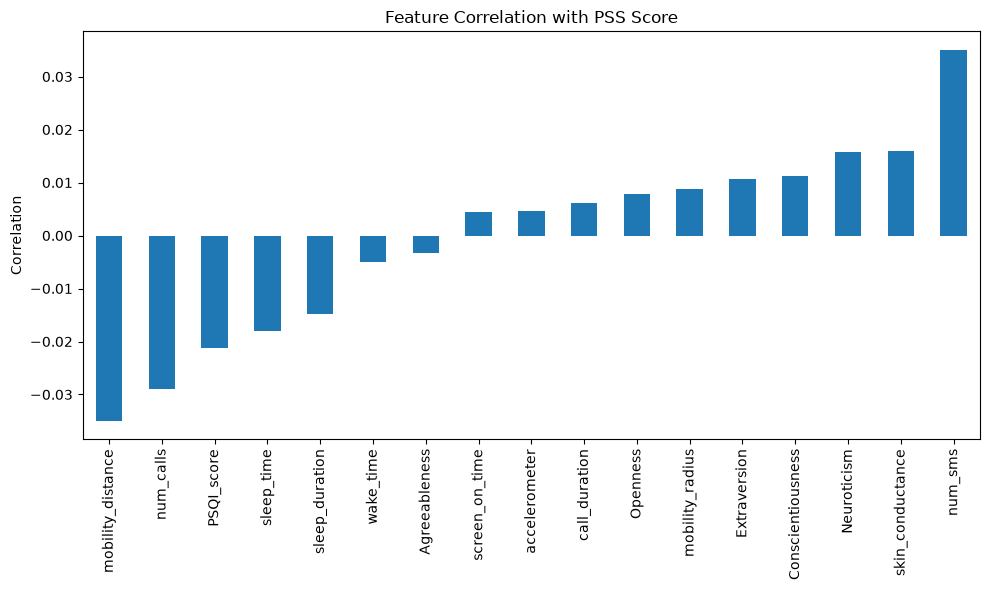

In [14]:
plt.figure(figsize=(10, 6))

correlations.drop("PSS_score").plot(kind="bar")

plt.title("Feature Correlation with PSS Score")
plt.ylabel("Correlation")
plt.tight_layout()
plt.show()

In [15]:
print("PSS mean:", y_train.mean())

baseline_predictions = np.full(len(y_test), y_train.mean())

print(
    "Baseline MAE:",
    mean_absolute_error(y_test, baseline_predictions)
)

print(
    "Baseline R²:",
    r2_score(y_test, baseline_predictions)
)

PSS mean: 24.719166666666666
Baseline MAE: 7.695
Baseline R²: -0.00010690631918297555


In [16]:
id="4k2q1f"
autocorr = (
    df.groupby("participant_id")["PSS_score"]
      .apply(lambda x: x.autocorr())
)

print(autocorr.describe())
print("Average autocorrelation:", autocorr.mean())


count    100.000000
mean      -0.027027
std        0.189123
min       -0.495020
25%       -0.156198
50%       -0.021081
75%        0.084527
max        0.330244
Name: PSS_score, dtype: float64
Average autocorrelation: -0.02702654496604514


In [17]:
df = df.sort_values(["participant_id", "day"]).copy()

behavior_features = [
    "sleep_duration",
    "PSQI_score",
    "screen_on_time",
    "call_duration",
    "num_calls",
    "num_sms",
    "skin_conductance",
    "mobility_distance"
]

for feature in behavior_features:
    df[f"{feature}_change"] = (
        df.groupby("participant_id")[feature].diff()
    )

    df[f"{feature}_rolling_mean"] = (
        df.groupby("participant_id")[feature]
        .transform(lambda x: x.rolling(3, min_periods=1).mean())
    )

print(df.shape)


(3000, 36)


In [18]:
engineered_features = [
    f"{feature}_change"
    for feature in behavior_features
] + [
    f"{feature}_rolling_mean"
    for feature in behavior_features
]

features_v2 = features + engineered_features

X = df[features_v2]
y = df["PSS_score"]
groups = df["participant_id"]

In [19]:
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X, y, groups)
)

X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]

y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

print(X_train.shape)
print(X_test.shape)


(2400, 33)
(600, 33)


In [20]:
# Handle missing values created by feature engineering
X = X.fillna(X.median())

print("Missing values:", X.isna().sum().sum())


splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X, y, groups)
)

X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]

Missing values: 0


In [21]:
for name, model in models_v2.items():
    model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r2 = r2_score(y_test, predictions)

    print(f"\n{name}")
    print(f"MAE: {mae:.3f}")
    print(f"RMSE: {rmse:.3f}")
    print(f"R²: {r2:.3f}")

NameError: name 'models_v2' is not defined

In [ ]:
df["target_next_day"] = (
    df.groupby("participant_id")["PSS_score"].shift(-1)
)

print(df[["participant_id", "day", "PSS_score", "target_next_day"]].head(10))

   participant_id  day  PSS_score  target_next_day
0               1    1         34             37.0
1               1    2         37             30.0
2               1    3         30             16.0
3               1    4         16             32.0
4               1    5         32             28.0
5               1    6         28             39.0
6               1    7         39             19.0
7               1    8         19             22.0
8               1    9         22             15.0
9               1   10         15             27.0


In [ ]:
df_next = df.dropna(subset=["target_next_day"]).copy()

print("Rows:", len(df_next))
print("Participants:", df_next["participant_id"].nunique())

Rows: 2900
Participants: 100


In [26]:
df = df.sort_values(["participant_id", "day"]).copy()

df["target_next_day"] = (
    df.groupby("participant_id")["PSS_score"].shift(-1)
)

print(df[["participant_id", "day", "PSS_score", "target_next_day"]].head(10))

   participant_id  day  PSS_score  target_next_day
0               1    1         34             37.0
1               1    2         37             30.0
2               1    3         30             16.0
3               1    4         16             32.0
4               1    5         32             28.0
5               1    6         28             39.0
6               1    7         39             19.0
7               1    8         19             22.0
8               1    9         22             15.0
9               1   10         15             27.0


In [27]:
df_next = df.dropna(subset=["target_next_day"]).copy()

print("Rows:", len(df_next))
print("Participants:", df_next["participant_id"].nunique())

Rows: 2900
Participants: 100


In [28]:
prediction_features = [
    "PSS_score",
    "Openness",
    "Conscientiousness",
    "Extraversion",
    "Agreeableness",
    "Neuroticism",
    "sleep_time",
    "wake_time",
    "sleep_duration",
    "PSQI_score",
    "call_duration",
    "num_calls",
    "num_sms",
    "screen_on_time",
    "skin_conductance",
    "accelerometer",
    "mobility_radius",
    "mobility_distance"
]

X_next = df_next[prediction_features]
y_next = df_next["target_next_day"]
groups_next = df_next["participant_id"]

print("Features:", X_next.shape)
print("Target:", y_next.shape)

Features: (2900, 18)
Target: (2900,)


In [29]:
from sklearn.model_selection import GroupShuffleSplit

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X_next, y_next, groups_next)
)

X_train = X_next.iloc[train_idx]
X_test = X_next.iloc[test_idx]

y_train = y_next.iloc[train_idx]
y_test = y_next.iloc[test_idx]

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Training participants:", groups_next.iloc[train_idx].nunique())
print("Testing participants:", groups_next.iloc[test_idx].nunique())

Training samples: 2320
Testing samples: 580
Training participants: 80
Testing participants: 20


In [30]:
models_next = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(
        n_estimators=300,
        random_state=42,
        n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=300,
        random_state=42
    )
}

for name, model in models_next.items():
    model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r2 = r2_score(y_test, predictions)

    print(f"\n{name}")
    print(f"MAE: {mae:.3f}")
    print(f"RMSE: {rmse:.3f}")
    print(f"R²: {r2:.3f}")



Linear Regression
MAE: 7.669
RMSE: 8.758
R²: 0.001

Random Forest
MAE: 7.771
RMSE: 8.913
R²: -0.035

Gradient Boosting
MAE: 7.988
RMSE: 9.210
R²: -0.105


In [31]:
behavior_only = [
    "Openness",
    "Conscientiousness",
    "Extraversion",
    "Agreeableness",
    "Neuroticism",
    "sleep_time",
    "wake_time",
    "sleep_duration",
    "PSQI_score",
    "call_duration",
    "num_calls",
    "num_sms",
    "screen_on_time",
    "skin_conductance",
    "accelerometer",
    "mobility_radius",
    "mobility_distance"
]

X_behavior = df_next[behavior_only]
y_behavior = df_next["target_next_day"]
groups_behavior = df_next["participant_id"]

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X_behavior, y_behavior, groups_behavior)
)

X_train_b = X_behavior.iloc[train_idx]
X_test_b = X_behavior.iloc[test_idx]
y_train_b = y_behavior.iloc[train_idx]
y_test_b = y_behavior.iloc[test_idx]

print(X_train_b.shape)
print(X_test_b.shape)

(2320, 17)
(580, 17)


In [32]:
model_behavior = RandomForestRegressor(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)

model_behavior.fit(X_train_b, y_train_b)

predictions = model_behavior.predict(X_test_b)

print("MAE:", mean_absolute_error(y_test_b, predictions))
print("RMSE:", np.sqrt(mean_squared_error(y_test_b, predictions)))
print("R²:", r2_score(y_test_b, predictions))


MAE: 7.773982758620689
RMSE: 8.922757321500502
R²: -0.037047946987256664


In [33]:
final_model = LinearRegression()

final_model.fit(X_next, y_next)

print("Final model trained successfully")

Final model trained successfully


In [34]:
import joblib
joblib.dump(final_model,"../models/stress_model.joblib")
print("Model Saved")

Model Saved
